# Supplementary Figure S14c. Pathway enrichment of the two colocalized inhibitory-neuron trans-ePrograms

Over-representation analysis (ConsensusPathDB) of inhibitory-neuron Hotspot *trans*-ePrograms 59 (215 genes) and 115 (156 genes), which colocalize with AD at the MS4A locus. As in the author's figure, a hand-picked subset of reported pathways is shown (3 for module 59, 5 for module 115; `selected_in_figure`); the full result tables are in the rds. The x-axis is $-\log_{10}$ nominal p, point size the number of program genes in the pathway.

Statistical note: the caption states FDR < 5%, but only "MECP2 regulates transcription of neuronal ligands" (module 59, q = 0.023) has q < 0.05; the other shown pathways have q = 0.112 (module 59) and q = 0.055 (module 115). The q-values are shown in the printed table. (The source result file for module 59 is named `..._module50.tab`; its overlap genes are all members of module 59.)

Input: `data/Figure_S14c_Inh_program_pathways.rds`


In [1]:
library(ggplot2)
library(patchwork)
d <- readRDS("data/Figure_S14c_Inh_program_pathways.rds")
d$label <- d$pathway
subset(d, selected_in_figure)[, c("program", "pathway", "p_value", "q_value", "overlap_n", "overlap_genes", "rank_by_p")]

,program,pathway,p_value,q_value,overlap_n,overlap_genes,rank_by_p
,<chr>,<chr>,<dbl>,<dbl>,<int>,<chr>,<int>
1,Inh. neuron trans-eProgram (Module 59),MECP2 regulates transcription of neuronal ligands,5.970766e-05,0.02316657,3,HDAC1;DLL1;MECP2,1
5,Inh. neuron trans-eProgram (Module 59),Transcriptional Regulation by MECP2,4.426085e-03,0.11243810,4,HDAC1;DLL1;MECP2;MOV10,5
6,Inh. neuron trans-eProgram (Module 59),Regulation of MECP2 expression and activity,5.233904e-03,0.11243810,3,HDAC1;MECP2;MOV10,6
27,Inh. neuron trans-eProgram (Module 115),Association of TriC/CCT with target proteins during biosynthesis,2.905592e-04,0.05497042,4,SKIV2L;CCNE1;FBXO6;AP3M1,1
29,Inh. neuron trans-eProgram (Module 115),Chaperonin-mediated protein folding,1.026288e-03,0.05497042,5,GNG4;SKIV2L;CCNE1;AP3M1;FBXO6,3
30,Inh. neuron trans-eProgram (Module 115),Gap-filling DNA repair synthesis and ligation in GG-NER,1.106032e-03,0.05497042,3,RFC5;RFC2;LIG3,4
31,Inh. neuron trans-eProgram (Module 115),Protein folding,1.298061e-03,0.05497042,5,GNG4;SKIV2L;CCNE1;AP3M1;FBXO6,5
32,Inh. neuron trans-eProgram (Module 115),Nectin/Necl trans heterodimerization,1.382904e-03,0.05497042,2,NECTIN2;PVR,6


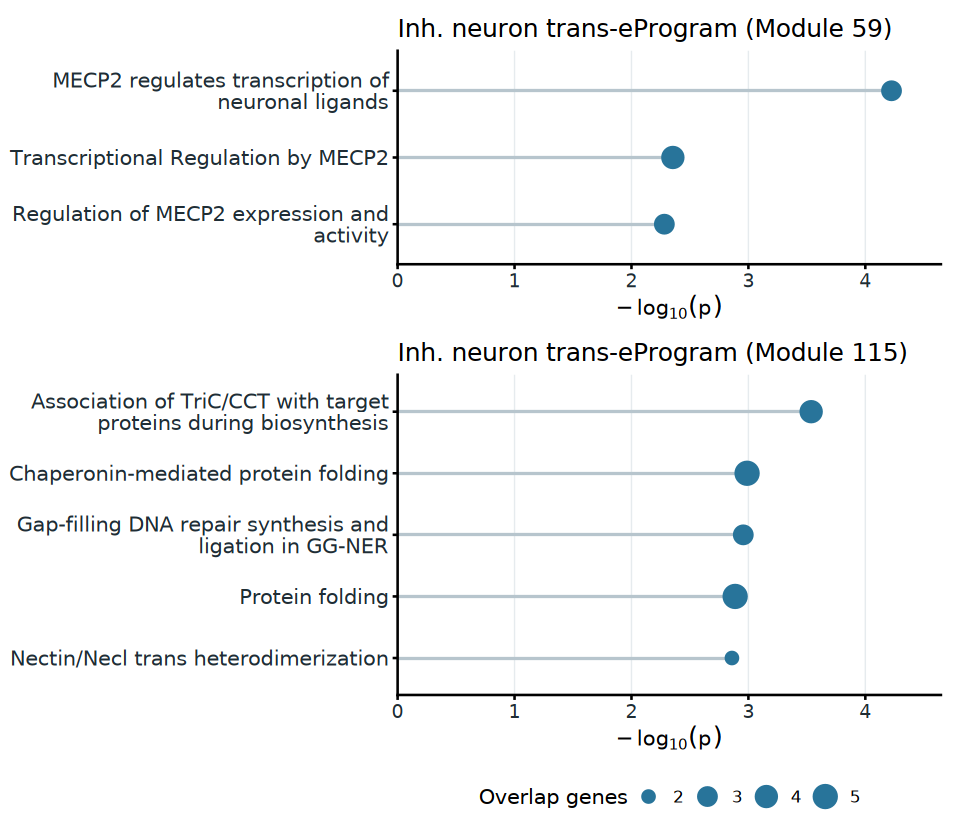

In [2]:
lollipop <- function(d, title, colour = "#28749A", wrap = 45, size_breaks = NULL, xmax = NULL) {
  if (is.null(xmax)) xmax <- max(d$neg_log10_p) * 1.1
  d <- d[order(d$p_value, d$pathway), ]
  d$label <- vapply(d$label, function(x) paste(strwrap(x, width = wrap), collapse = "\n"), character(1))
  d$label <- factor(d$label, levels = rev(d$label))
  ggplot(d, aes(x = neg_log10_p, y = label)) +
    geom_segment(aes(x = 0, xend = neg_log10_p, yend = label), colour = "#B7C5CD", linewidth = 0.7) +
    geom_point(aes(size = overlap_n), colour = colour) +
    scale_size_continuous(name = "Overlap genes", range = c(3, 6),
                          breaks = if (is.null(size_breaks)) sort(unique(d$overlap_n)) else size_breaks,
                          limits = if (is.null(size_breaks)) NULL else range(size_breaks)) +
    scale_x_continuous(limits = c(0, xmax), expand = expansion(mult = c(0, 0))) +
    labs(title = title, x = expression(-log[10](italic(p))), y = NULL) +
    theme_classic(base_size = 12) +
    theme(axis.text.y = element_text(size = 12, colour = "#1F2D35", lineheight = 0.9),
          axis.text.x = element_text(size = 11, colour = "#1F2D35"),
          legend.position = "bottom",
          panel.grid.major.x = element_line(colour = "#E6EBEE", linewidth = 0.3))
}

s <- subset(d, selected_in_figure)
br <- sort(unique(s$overlap_n))
xmax <- max(s$neg_log10_p) * 1.1
p59  <- lollipop(subset(s, grepl("59", program)),  "Inh. neuron trans-eProgram (Module 59)",  size_breaks = br, wrap = 40, xmax = xmax)
p115 <- lollipop(subset(s, grepl("115", program)), "Inh. neuron trans-eProgram (Module 115)", size_breaks = br, wrap = 40, xmax = xmax)
p <- p59 / p115 + plot_layout(heights = c(0.4, 0.6), guides = "collect") &
  theme(legend.position = "bottom")
options(repr.plot.width = 8, repr.plot.height = 7)
p